In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

URL = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv'
df = pd.read_csv(URL)
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
print(df.isnull().sum())
df.describe().T

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [3]:
def engineer(d):
    d = d.copy()
    # ratios
    d['rooms_per_household']      = d['total_rooms'] / d['households']
    d['bedrooms_per_room']        = d['total_bedrooms'] / d['total_rooms']
    d['population_per_household'] = d['population'] / d['households']
    # interactions
    d['income_x_rooms'] = d['median_income'] * d['rooms_per_household']
    d['income_x_age']   = d['median_income'] * d['housing_median_age']
    d['lat_x_long']     = d['latitude'] * d['longitude']
    return d

df_fe = engineer(df)
df_fe.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms,income_x_age,lat_x_long
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,58.144254,341.3332,-4630.0724
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,51.785271,174.3294,-4627.2492
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,60.150315,377.3848,-4626.7840
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,32.827897,293.4412,-4627.1625
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,24.161264,200.0024,-4627.1625


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df_fe.drop(columns='median_house_value')
y = df_fe['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = X.select_dtypes('number').columns.tolist()
cat_cols = ['ocean_proximity']

preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc',  StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

print(len(num_cols), 'numeric features')
print(X_train.shape, X_test.shape)

14 numeric features
(16512, 15) (4128, 15)


In [5]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

ols = Pipeline([('prep', preprocess), ('m', LinearRegression())])
ols.fit(X_train, y_train)
print('OLS fitted')

OLS fitted


In [6]:
from sklearn.model_selection import GridSearchCV

ridge_gs = GridSearchCV(
    Pipeline([('prep', preprocess), ('m', Ridge())]),
    param_grid={'m__alpha': np.logspace(-3, 3, 13)},
    cv=5,
    scoring='neg_root_mean_squared_error'
)
ridge_gs.fit(X_train, y_train)
print('Best Ridge alpha:', ridge_gs.best_params_['m__alpha'])

Best Ridge alpha: 0.001


In [7]:
lasso_gs = GridSearchCV(
    Pipeline([('prep', preprocess), ('m', Lasso(max_iter=5000, tol=1e-3))]),
    param_grid={'m__alpha': np.logspace(-1, 3.5, 12)},
    cv=5,
    scoring='neg_root_mean_squared_error'
)
lasso_gs.fit(X_train, y_train)
print('Best Lasso alpha:', lasso_gs.best_params_['m__alpha'])

Best Lasso alpha: 0.1


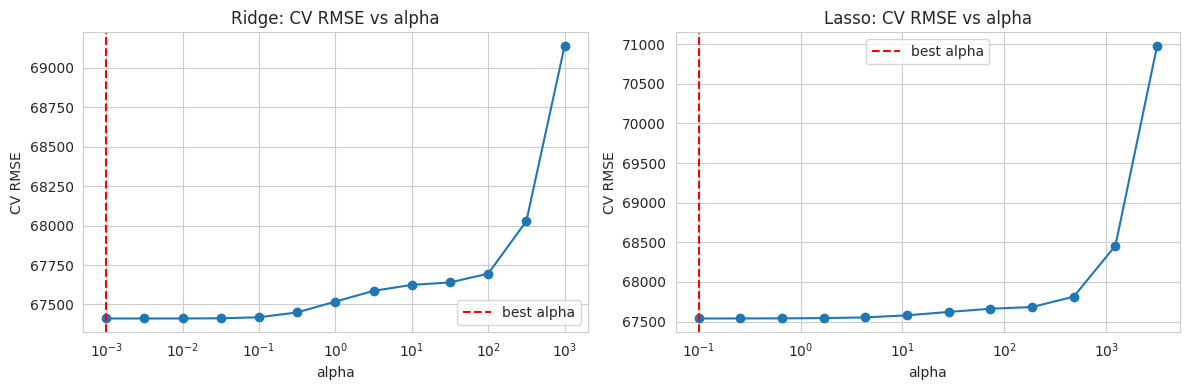

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, gs, name in [(ax[0], ridge_gs, 'Ridge'), (ax[1], lasso_gs, 'Lasso')]:
    r = gs.cv_results_
    a.semilogx(r['param_m__alpha'].data.astype(float), -r['mean_test_score'], 'o-')
    a.axvline(gs.best_params_['m__alpha'], color='r', ls='--', label='best alpha')
    a.set_title(name + ': CV RMSE vs alpha')
    a.set_xlabel('alpha')
    a.set_ylabel('CV RMSE')
    a.legend()
plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {'OLS': ols, 'Ridge': ridge_gs.best_estimator_, 'Lasso': lasso_gs.best_estimator_}

rows, preds = [], {}
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    rows.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_test, p)),
        'MAE': mean_absolute_error(y_test, p),
        'R2': r2_score(y_test, p),
        'Train R2': r2_score(y_train, m.predict(X_train))
    })

results = pd.DataFrame(rows).set_index('Model').round(4)
results

,RMSE,MAE,R2,Train R2
Model,,,,
OLS,68528.4137,49164.3245,0.6416,0.6629
Ridge,68528.5667,49164.4678,0.6416,0.6629
Lasso,68711.8378,49341.7065,0.6397,0.6616


In [10]:
ohe_names = ols.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_cols)
feat = num_cols + list(ohe_names)

coefs = pd.DataFrame({n: m.named_steps['m'].coef_ for n, m in models.items()}, index=feat)
print('Lasso zeroed-out features:', list(coefs.index[coefs['Lasso'] == 0]))
coefs.round(0).sort_values('OLS', key=abs, ascending=False)

Lasso zeroed-out features: []


,OLS,Ridge,Lasso
lat_x_long,729023.0,727796.0,202121.0
latitude,530281.0,529293.0,105392.0
longitude,-208390.0,-208135.0,-99071.0
ocean_proximity_ISLAND,135460.0,135419.0,131545.0
median_income,80111.0,80113.0,80894.0
population,-45968.0,-45967.0,-45587.0
ocean_proximity_INLAND,-41782.0,-41769.0,-36105.0
households,36973.0,36973.0,37046.0
bedrooms_per_room,18109.0,18110.0,18576.0
income_x_rooms,-13924.0,-13925.0,-14304.0


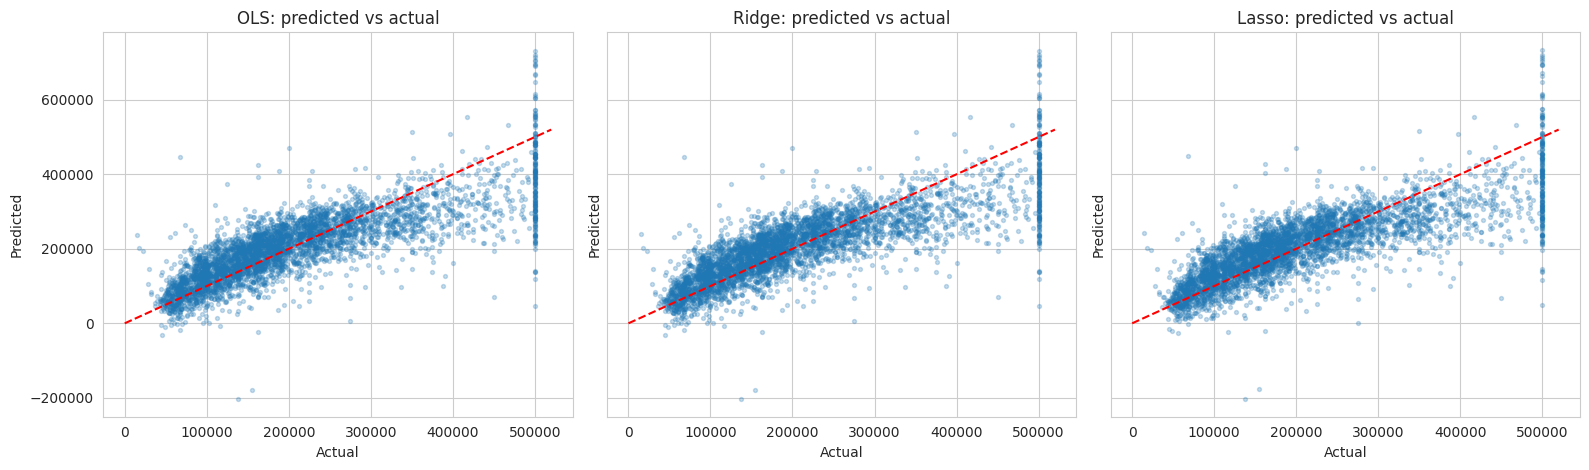

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
lim = [0, 520000]
for a, (name, p) in zip(ax, preds.items()):
    a.scatter(y_test, p, alpha=0.25, s=8)
    a.plot(lim, lim, 'r--')
    a.set_title(name + ': predicted vs actual')
    a.set_xlabel('Actual')
    a.set_ylabel('Predicted')
plt.tight_layout()
plt.show()

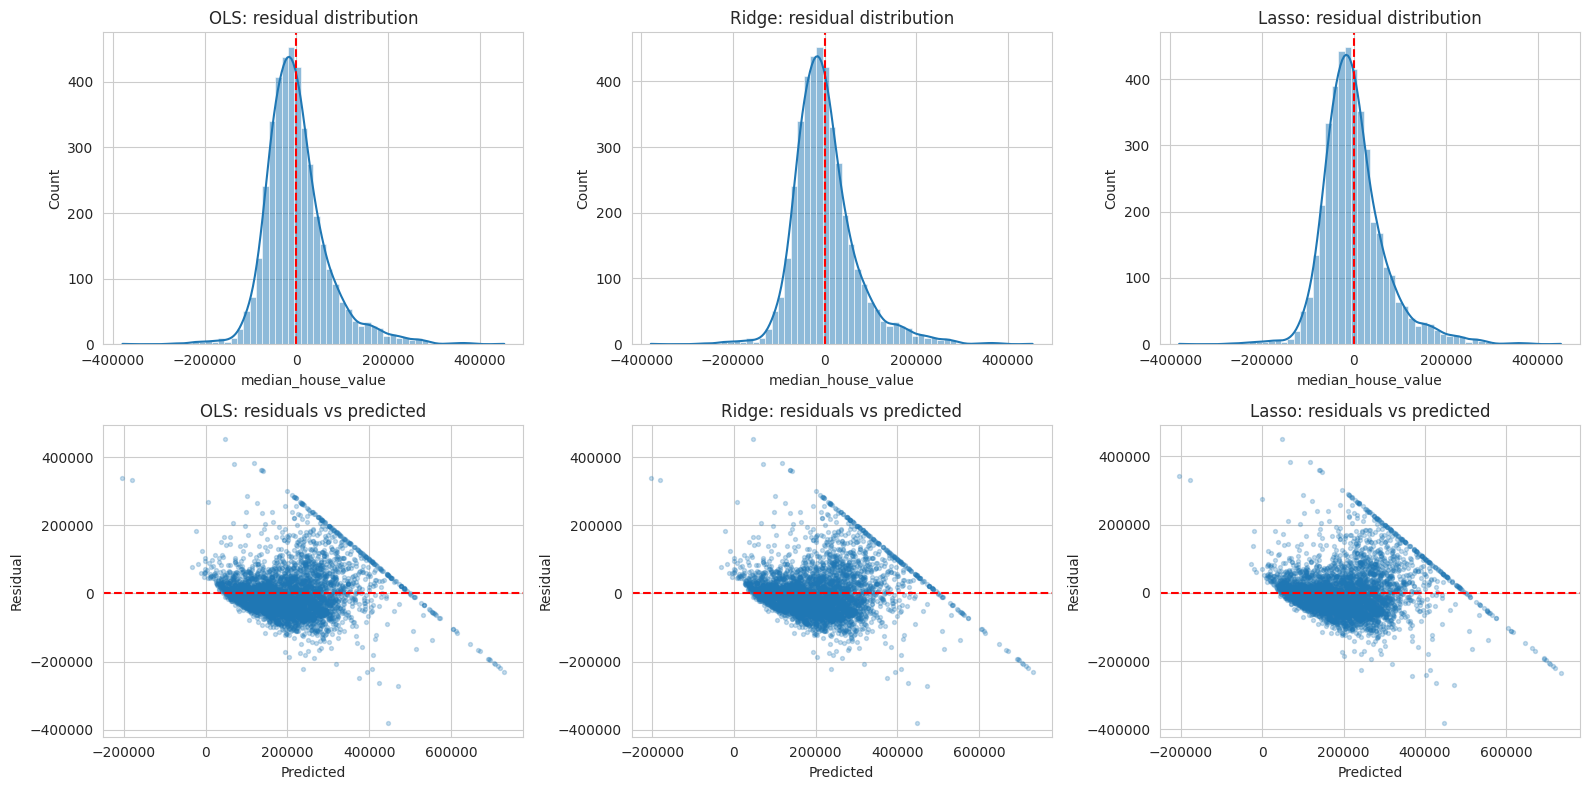

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for j, (name, p) in enumerate(preds.items()):
    res = y_test - p

    sns.histplot(res, kde=True, bins=60, ax=ax[0, j])
    ax[0, j].axvline(0, color='r', ls='--')
    ax[0, j].set_title(name + ': residual distribution')

    ax[1, j].scatter(p, res, alpha=0.25, s=8)
    ax[1, j].axhline(0, color='r', ls='--')
    ax[1, j].set_xlabel('Predicted')
    ax[1, j].set_ylabel('Residual')
    ax[1, j].set_title(name + ': residuals vs predicted')
plt.tight_layout()
plt.show()

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# impute + standardize the numeric training columns
Xi = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_train[num_cols]), columns=num_cols)
Xi = (Xi - Xi.mean()) / Xi.std()
Xi['const'] = 1

vif = pd.Series(
    [variance_inflation_factor(Xi.values, i) for i in range(len(num_cols))],
    index=num_cols
).sort_values(ascending=False)

vif.round(1).to_frame('VIF')

,VIF
lat_x_long,13243.4
latitude,8339.8
longitude,649.3
total_bedrooms,51.0
households,47.1
median_income,21.1
total_rooms,19.6
income_x_rooms,18.0
income_x_age,9.2
population,6.9


## Conclusions

**Model comparison (test set)**

| Model | RMSE | MAE | R² |
|---|---|---|---|
| OLS | ~68,500 | ~49,200 | ~0.64 |
| Ridge | ~68,500 | ~49,200 | ~0.64 |
| Lasso | ~68,700 | ~49,300 | ~0.64 |

**Findings**
- All three models perform almost identically. OLS is marginally best, Ridge is effectively the same, and Lasso is slightly worse.
- GridSearchCV chose the smallest alphas in the grids (Ridge ≈ 0.001, Lasso ≈ 0.1). With about 20k rows and 15 features, OLS does not overfit (train R² ≈ test R²), so regularization has little to fix.
- Multicollinearity is clearly present (high VIF for lat/long, room and bedroom counts, and the interaction terms). It makes individual OLS coefficients unstable, but it barely affects predictive accuracy.
- Residuals fan out as predictions rise (heteroscedasticity) and pile up at the $500k cap in the target. This is a limit of linear models, not of the tuning.

**Next steps**
- Log-transform the target, add non-linear features, or try tree-based models such as Random Forest or Gradient Boosting.